# Reinforcement Learning: In-Class Lab

*Companion to the Deep Reinforcement Learning deck. Run every cell in order (Runtime > Run all). Pure `numpy` and `matplotlib`, no setup needed.*

An RL agent learns by trying actions and seeing rewards. We build two tiny agents:

1. a **multi-armed bandit** that learns which of four assets pays best, and
2. a **Q-learning** agent that learns to cross a small gridworld.

The bandit shows the heart of RL (explore vs exploit). The gridworld adds **state**, which is the step from a bandit to real reinforcement learning.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)  # reproducible: everyone sees the same run
PURPLE, ORANGE, LAV, NAVY = "#3333B2", "#FF7F0E", "#ADADE0", "#1e3a5f"
print("ready")

ready


## Part 1: The Multi-Armed Bandit (choosing an asset)

Imagine four investment strategies. Each pays a noisy return whose average edge is **hidden**. Every round the agent puts money in one of them and sees the payoff. Its goal: earn as much as possible over many rounds.

The tension: it must **explore** (try assets to learn their edge) yet also **exploit** (keep using the best one found so far).

In [2]:
# Four "assets" (strategies). Each pays a noisy reward whose hidden mean is its
# true edge. The agent does NOT see these means; it must learn them by trying.
K = 4
asset_names = ["Bonds", "Blue-chip", "Growth", "Crypto"]
true_means = np.array([0.20, 0.50, 0.80, 0.40])   # hidden from the agent

def pull(a):
    """Invest in asset a for one round; return a noisy reward."""
    return true_means[a] + np.random.normal(0, 0.5)

In [12]:
print("\nSample rewards (3 pulls per asset):")
print("-" * 50)

for a in range(K):
    rewards = [pull(a) for _ in range(3)]
    rewards_str = ", ".join(f"{r:6.2f}" for r in rewards)
    print(f"{asset_names[a]:<12} {rewards_str}")


Sample rewards (3 pulls per asset):
--------------------------------------------------
Bonds          0.29,   1.00,   1.30
Blue-chip      0.58,   0.69,   0.11
Growth         1.47,   0.78,   0.59
Crypto         0.02,   0.44,   0.71


**CHECKPOINT (predict before you run the next cell).** Asset 2 (`Growth`) has the highest hidden mean (0.80). Will a few noisy pulls reliably reveal that? What does the agent need to do?

Now the agent. The one line that matters is the **epsilon-greedy** choice: with probability `epsilon` explore a random asset, otherwise exploit the best estimate so far. *Exercise: try to write that `if` block yourself before reading it.*

In [13]:
def run_bandit(epsilon, steps=2000):
    Q = np.zeros(K)            # value estimate per asset (starts at 0)
    N = np.zeros(K)            # number of times each asset was chosen
    rewards = np.zeros(steps)
    optimal = np.zeros(steps)
    best = int(np.argmax(true_means))
    for t in range(steps):
        # Epsilon-greedy choice (the key RL line):
        if np.random.rand() < epsilon:
            a = np.random.randint(K)       # EXPLORE: try a random asset
        else:
            a = int(np.argmax(Q))          # EXPLOIT: pick the best estimate so far
        r = pull(a)
        N[a] += 1
        Q[a] += (r - Q[a]) / N[a]          # running-average value update
        rewards[t] = r
        optimal[t] = (a == best)
    return Q, rewards, optimal

Estimated values: [0.23 0.5  0.79 0.44]
True values:      [0.2 0.5 0.8 0.4]
Agent's favourite: Growth


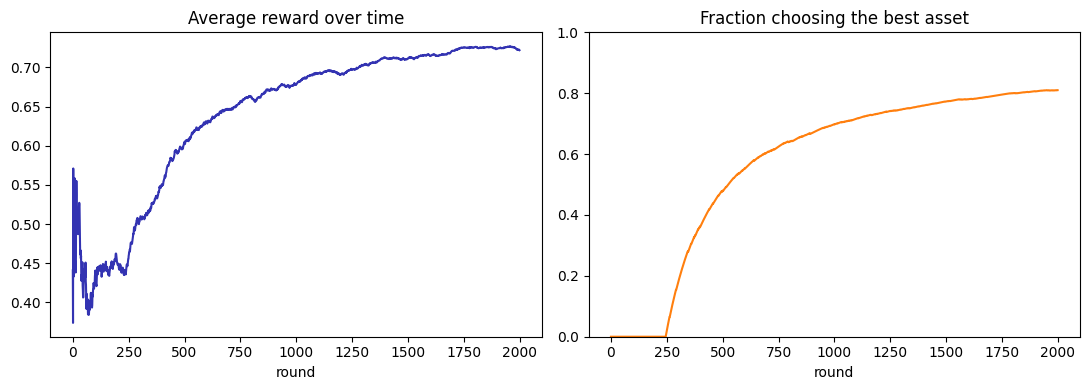

In [14]:
Q, rewards, optimal = run_bandit(epsilon=0.1)
print("Estimated values:", np.round(Q, 2))
print("True values:     ", true_means)
print("Agent's favourite:", asset_names[int(np.argmax(Q))])

steps = len(rewards)
x = np.arange(1, steps + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(np.cumsum(rewards) / x, color=PURPLE)
ax[0].set_title("Average reward over time"); ax[0].set_xlabel("round")
ax[1].plot(np.cumsum(optimal) / x, color=ORANGE)
ax[1].set_title("Fraction choosing the best asset"); ax[1].set_xlabel("round"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

**CHECKPOINT (predict before you run the next cell).** Before running the next cell: what happens if `epsilon = 0`, so the agent never explores?

In [15]:
# WRONG WAY: epsilon = 0 means the agent never explores. It grabs whatever
# looked good first and never discovers the truly best asset.
Q0, r0, opt0 = run_bandit(epsilon=0.0)
print("Pure-greedy estimates:", np.round(Q0, 2))
print("Locked onto:", asset_names[int(np.argmax(Q0))],
      "| truly best:", asset_names[int(np.argmax(true_means))])
print(f"Pure-greedy chose the best asset only {100*opt0.mean():.0f}% of the time.")

Pure-greedy estimates: [0.2 0.  0.  0. ]
Locked onto: Bonds | truly best: Growth
Pure-greedy chose the best asset only 0% of the time.


**Your turn (tweak).** Run the sweep below, then change the `epsilon` values and re-run. Which exploration rate earns the most? Why is too much exploring also bad?

In [17]:
# TWEAK: how does the exploration rate change performance? Re-run after editing.
for eps in [0.0, 0.01, 0.1, 0.3]:
    q, rewards, optimal = run_bandit(eps)
    print(f"epsilon={eps:<4}  avg reward={rewards.mean():.3f}   chose best={100*optimal.mean():.0f}%")



epsilon=0.0   avg reward=0.502   chose best=0%
epsilon=0.01  avg reward=0.710   chose best=70%
epsilon=0.1   avg reward=0.770   chose best=93%
epsilon=0.3   avg reward=0.699   chose best=76%


epsilon=0.0   avg reward=0.777   chose best=100%
Estimated values: [0.23 0.5  0.79 0.44]
True values:      [0.2 0.5 0.8 0.4]
Agent's favourite: Growth


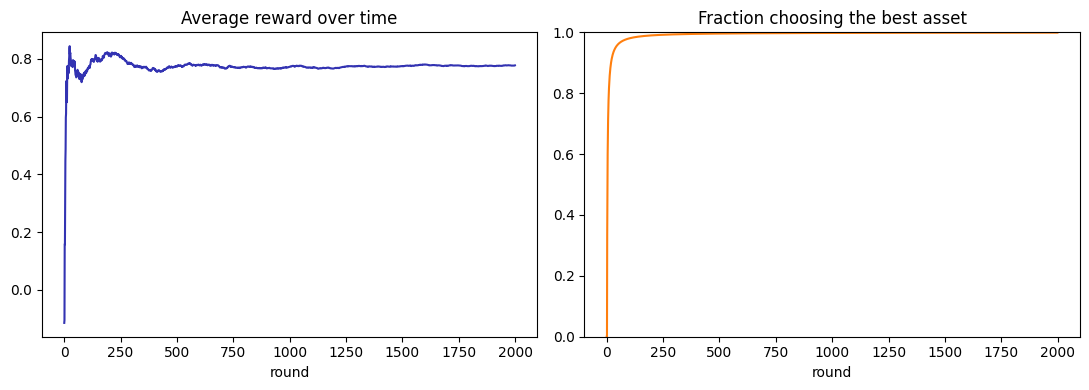

epsilon=0.01  avg reward=0.747   chose best=90%
Estimated values: [0.23 0.5  0.79 0.44]
True values:      [0.2 0.5 0.8 0.4]
Agent's favourite: Growth


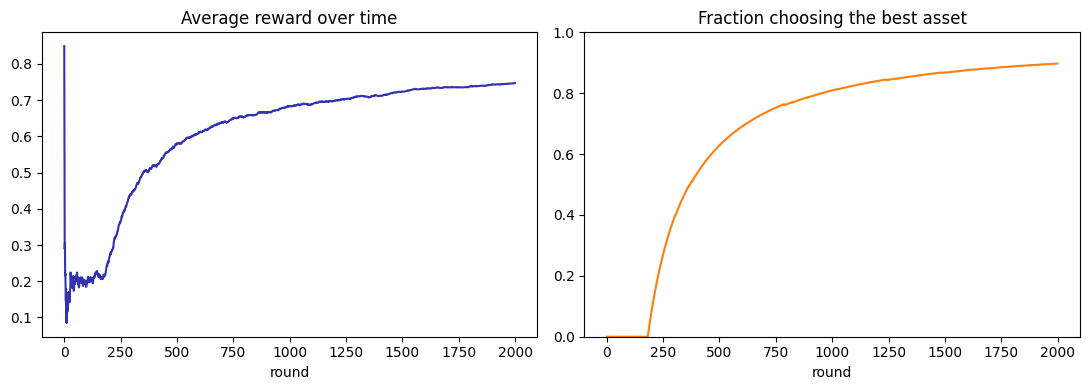

epsilon=0.1   avg reward=0.760   chose best=92%
Estimated values: [0.23 0.5  0.79 0.44]
True values:      [0.2 0.5 0.8 0.4]
Agent's favourite: Growth


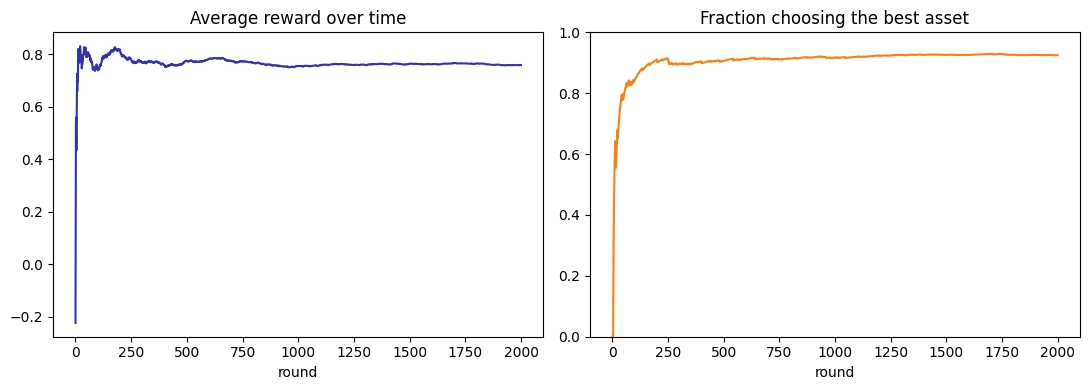

epsilon=0.3   avg reward=0.703   chose best=76%
Estimated values: [0.23 0.5  0.79 0.44]
True values:      [0.2 0.5 0.8 0.4]
Agent's favourite: Growth


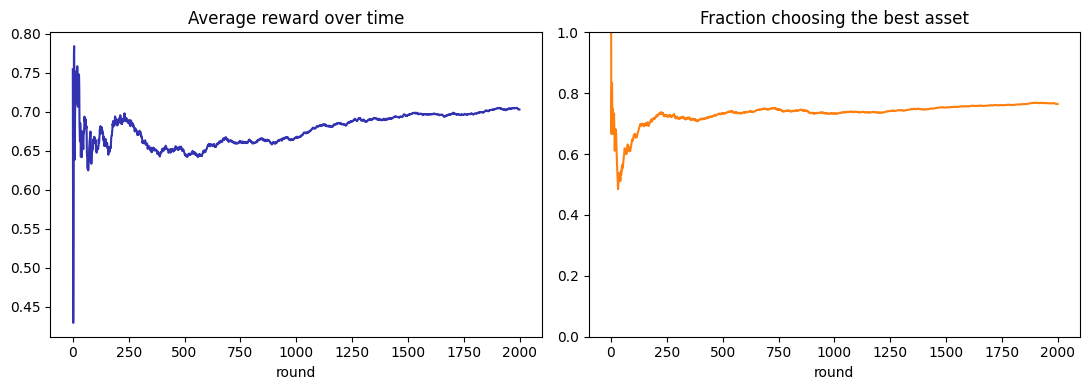

epsilon=0.8   avg reward=0.556   chose best=42%
Estimated values: [0.23 0.5  0.79 0.44]
True values:      [0.2 0.5 0.8 0.4]
Agent's favourite: Growth


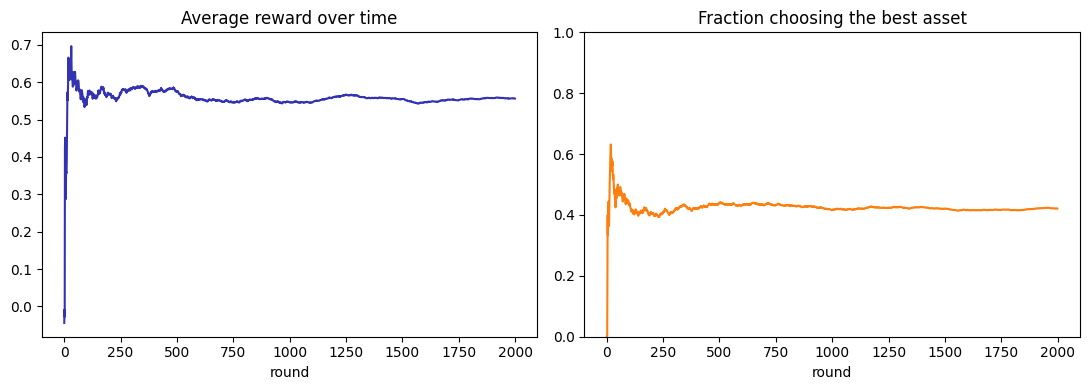

In [19]:
# TWEAK: how does the exploration rate change performance? Re-run after editing.
for eps in [0.0, 0.01, 0.1, 0.3, 0.8]:
    q, rewards, optimal = run_bandit(eps)
    print(f"epsilon={eps:<4}  avg reward={rewards.mean():.3f}   chose best={100*optimal.mean():.0f}%")


    print("Estimated values:", np.round(Q, 2))
    print("True values:     ", true_means)
    print("Agent's favourite:", asset_names[int(np.argmax(Q))])

    steps = len(rewards)
    x = np.arange(1, steps + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(np.cumsum(rewards) / x, color=PURPLE)
    ax[0].set_title("Average reward over time"); ax[0].set_xlabel("round")
    ax[1].plot(np.cumsum(optimal) / x, color=ORANGE)
    ax[1].set_title("Fraction choosing the best asset"); ax[1].set_xlabel("round"); ax[1].set_ylim(0, 1)
    plt.tight_layout(); plt.show()

## Part 2: From Bandit to Q-Learning (adding state)

A bandit has **one** situation: pick an asset. Real problems have many situations (states) and choices that move you between them. We add the smallest possible state: position in a corridor. This is the deck's gridworld, and it uses the **Bellman update** from the slides.

In [8]:
# A 1-D gridworld: a corridor of 5 cells. Start at cell 0, goal at cell 4.
# Reaching the goal pays +1. Now the agent has a STATE (which cell it is in),
# which the bandit did not. This is the deck's gridworld, in one dimension.
n_states = 5
goal = 4
n_actions = 2  # 0 = left, 1 = right

def step(s, a):
    s2 = max(0, s - 1) if a == 0 else min(n_states - 1, s + 1)
    reward = 1.0 if s2 == goal else 0.0
    done = (s2 == goal)
    return s2, reward, done

The agent learns `Q[state, action]`, the value of each move in each cell, using the Bellman update `Q[s,a] += alpha * (r + gamma * max(Q[s']) - Q[s,a])`. *Exercise: find that line in the next cell and say in words what each piece (`r`, `gamma * max(Q[s'])`, `- Q[s,a]`) means.*

In [9]:
def q_learning(alpha=0.5, gamma=0.9, epsilon=0.2, episodes=300):
    Q = np.zeros((n_states, n_actions))   # value of each action in each cell
    returns = np.zeros(episodes)
    for ep in range(episodes):
        s, total, done, t = 0, 0.0, False, 0
        while not done and t < 50:
            if np.random.rand() < epsilon:
                a = np.random.randint(n_actions)   # explore
            else:
                a = int(np.argmax(Q[s]))           # exploit
            s2, r, done = step(s, a)
            # Bellman update: the deck's Q(s,a) <- r + gamma * max_a' Q(s', a')
            Q[s, a] += alpha * (r + gamma * np.max(Q[s2]) - Q[s, a])
            s, total, t = s2, total + r, t + 1
        returns[ep] = total
    return Q, returns

**CHECKPOINT (predict before you run the next cell).** The goal is at the right end (cell 4) and only moving right ever earns reward. After training, which action should have the higher Q-value in every cell, left or right?

Learned Q-values (rows = cell 0..4, columns = [left, right]):
[[0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]]


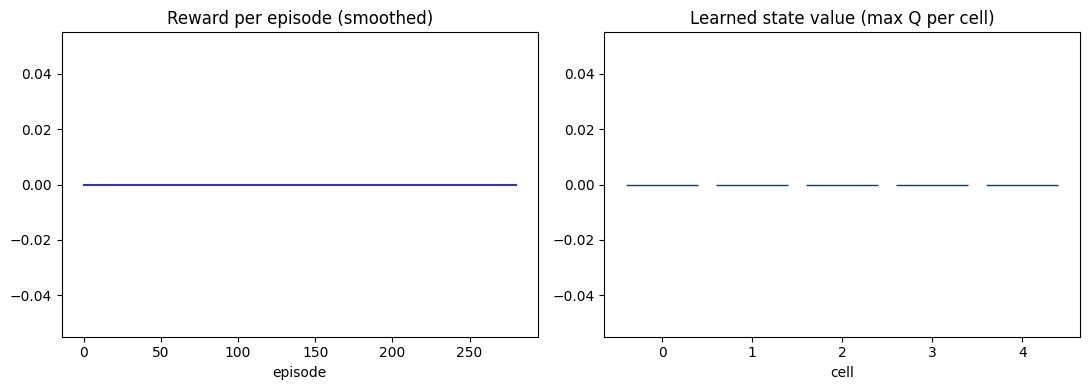

In [10]:
Q, returns = q_learning()
print("Learned Q-values (rows = cell 0..4, columns = [left, right]):")
print(np.round(Q, 2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(np.convolve(returns, np.ones(20) / 20, mode="valid"), color=PURPLE)
ax[0].set_title("Reward per episode (smoothed)"); ax[0].set_xlabel("episode")
ax[1].bar(range(n_states), Q.max(axis=1), color=LAV, edgecolor=NAVY)
ax[1].set_title("Learned state value (max Q per cell)"); ax[1].set_xlabel("cell")
plt.tight_layout(); plt.show()

## Wrap-up

- The **bandit** is RL stripped to its core: balance exploring and exploiting to maximise reward. `epsilon = 0` (never explore) is the classic trap.
- **Q-learning** adds state and the **Bellman update**: a cell is worth its reward now plus the discounted value of where it leads. The learned values rise toward the goal, exactly as the deck's gridworld shows.
- We skipped what comes next in the deck: replacing the table with a network (**DQN**) and learning the policy directly (**policy gradients**).

**Finance caveat.** This corridor and these four assets are toys. A real market is noisy, non-stationary, and adversarial. The deck's *Limits* section (sample inefficiency, the backtest illusion, reward hacking, drawdowns) is the part to take to heart before trusting any RL agent with money.